# Baseline Model

In [2]:
#Possible future iterations
 # Explore grouping country code in some way, so low freq codes are grouped
 # bin type, bin brand - Sandrina

#Review warning from the pd.to_datetime - Jose


#Possible exploration opportunities - payment_method, session_visitor_time, avs_code

#Imbalances - any different approach to it or stay with stratrify in train_test_split, even worth having it there?

In [147]:
import os
import base64
import joblib
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import cross_val_score
from category_encoders import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score, confusion_matrix, pairwise, precision_recall_curve, roc_curve
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from sklearn.base import BaseEstimator, TransformerMixin

import category_encoders as ce
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, average_precision_score
from sklearn.model_selection import GridSearchCV


import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


from sklearn.feature_selection import mutual_info_classif

%matplotlib inline

### Extract Data

In [4]:
#Import train data and have a quick glimpse to the content and shape
data = pd.read_csv("data/train.csv")
data.shape

(195401, 16)

In [5]:
data.head()

,order_id,order_date,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,shipping_method_type,card_expiration_date,bin_brand,bin_type,label,suspicious_activity_score
0,181852054,2022-06-02 15:28:13,611.03,payment_method_2,SA,SA,avs_code_8,NaN,NaN,returning,E,05/2025,mastercard,credit,0.0,7.801596
1,181265052,2022-05-21 15:53:20,334.44,payment_method_1,FR,FR,avs_code_1,591.141667,6.0,returning,S,NaN,NaN,NaN,0.0,8.117476
2,149633145,2021-09-30 09:05:06,611.85,payment_method_1,HK,HK,avs_code_1,NaN,NaN,returning,E;E,NaN,NaN,NaN,0.0,6.240885
3,149158895,2021-09-22 15:19:15,198.18,payment_method_2,RU,RU,avs_code_5,473.027368,38.0,returning,E,03/2023,visa,debit,0.0,5.188745
4,169664695,2022-02-18 08:59:32,434.71,payment_method_3,HK,HK,avs_code_5,NaN,NaN,returning,E,NaN,NaN,NaN,0.0,5.738602


In [6]:
feature_columns = list(data.drop(columns=['label']).columns)
numerical_feature_columns = 
target_column = 'label'

print(f"All potential feature columns:\n {feature_columns}")
print(f"\nTarget column: {target_column}")

All potential feature columns:
 ['order_id', 'order_date', 'amount_usd', 'payment_method', 'billing_address_country_code', 'shipping_address_country_code', 'avs_code', 'email_amount_spent_avg_180d', 'email_orders_count_180d', 'session_visitor_type', 'shipping_method_type', 'card_expiration_date', 'bin_brand', 'bin_type', 'suspicious_activity_score']

Target column: label


### General Exploratory Data Analysis

In [7]:
#Understand Data at High Level - And do our best guest simplistic approach to the problem
#1. Understand Data types - identify what needs to be converted - Ricardo
#2. Unique values per variable - identify what variables don't make sense (too many values/too granular), and which ones may be suitable for one hot encoding - Ricardo
#3. Number of missings - Ricardo
#4. Distribution of numerical varibles - outliers, what scaling makes sense? - Abdullah
#4.1 Categorical data analysis - Sandrina
#5. Duplicates (Jose) - explore cases where there we have the same order id multiple times, what does this mean? It seems we have multiple ids sometimes
#only one with a label - what does it mean? Mean different actions and then the label is on the final attempt? Should we drop the non-labelled?
#6. Class imabalance - Jose

# - Should we do the basic things together and then split between numerical and categorical and invest 1h on that independently? 

In [8]:
data.dtypes

order_id                           int64
order_date                        object
amount_usd                       float64
payment_method                    object
billing_address_country_code      object
shipping_address_country_code     object
avs_code                          object
email_amount_spent_avg_180d      float64
email_orders_count_180d          float64
session_visitor_type              object
shipping_method_type              object
card_expiration_date              object
bin_brand                         object
bin_type                          object
label                            float64
suspicious_activity_score        float64
dtype: object

In [9]:
data.nunique()

order_id                         190266
order_date                       174799
amount_usd                        83602
payment_method                        8
billing_address_country_code        166
shipping_address_country_code       166
avs_code                             24
email_amount_spent_avg_180d       82105
email_orders_count_180d             665
session_visitor_type                  2
shipping_method_type                156
card_expiration_date                187
bin_brand                            10
bin_type                              3
label                                 2
suspicious_activity_score        190343
dtype: int64

In [10]:
data.select_dtypes(include=["object", "category"]).nunique()

order_date                       174799
payment_method                        8
billing_address_country_code        166
shipping_address_country_code       166
avs_code                             24
session_visitor_type                  2
shipping_method_type                156
card_expiration_date                187
bin_brand                            10
bin_type                              3
dtype: int64

In [11]:
data.isnull().sum()

order_id                             0
order_date                           0
amount_usd                           0
payment_method                     622
billing_address_country_code        21
shipping_address_country_code       17
avs_code                          3467
email_amount_spent_avg_180d      95444
email_orders_count_180d          96131
session_visitor_type             35812
shipping_method_type                 0
card_expiration_date             60605
bin_brand                        61685
bin_type                         62099
label                               10
suspicious_activity_score            0
dtype: int64

In [12]:
data.select_dtypes(include=["object", "category"]).isnull().sum()

order_date                           0
payment_method                     622
billing_address_country_code        21
shipping_address_country_code       17
avs_code                          3467
session_visitor_type             35812
shipping_method_type                 0
card_expiration_date             60605
bin_brand                        61685
bin_type                         62099
dtype: int64

In [231]:
data.shipping_address_country_code.value_counts()

shipping_address_country_code
GB    29355
RU    13802
US    11321
DE    10441
IT     9427
      ...  
LC        1
VC        1
BF        1
BO        1
RW        1
Name: count, Length: 166, dtype: int64

In [13]:
# Analyze outliers
df = data.copy()
df_numerical = df.select_dtypes(include = np.number)
df_numerical_cols = df_numerical.columns
Q1 = df[df_numerical_cols].quantile(0.25)
Q3 = df[df_numerical_cols].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[df_numerical_cols] < (Q1 - 1.5 * IQR)) | (df[df_numerical_cols] > (Q3 + 1.5 * IQR))).sum()
outliers.sort_values(ascending=False)

suspicious_activity_score      19075
label                          17620
email_orders_count_180d        12840
amount_usd                      9268
email_amount_spent_avg_180d     5820
order_id                           0
dtype: int64

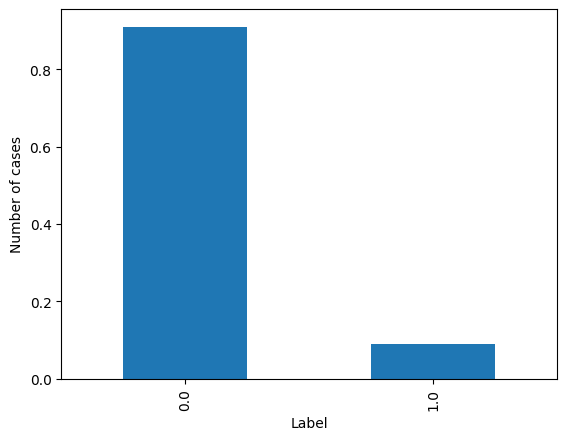

In [14]:
#Class Imabance Analysis
data.label.value_counts(normalize=True).plot(kind="bar");
plt.xlabel('Label');
plt.ylabel('Number of cases');

### Data Cleaning

##### Remove duplicates in the train data (not reproducible in Test as depends on the label)

In [15]:
data = data[data['label'].notna()].drop_duplicates()
data.shape

(190343, 16)

In [16]:
data.bin_type.value_counts(dropna=False)

bin_type
credit          80371
NaN             60408
debit           49536
credit/debit       28
Name: count, dtype: int64

In [172]:
#Apply the simplistic approach that we've came up with - Create a FeatureCleaner custom transformer
class DataCleaner(TransformerMixin):
    def __init__(self):
        pass
        
    def fit(self, X=None, y=None, **fit_params):
        return self
    
    def transform(self, X):
        _df = X.copy()

        # 0) Converdtypes
        _df['order_date']= pd.to_datetime(_df['order_date'], errors='coerce')
        _df['card_expiration_date'] = pd.to_datetime(_df['card_expiration_date'].astype(str).str.strip() + '/01', format='%m/%Y/%d', errors='coerce')
        
        # 1) Rename 'id'
        #_df = _df.rename(columns={'order_id':'id'})
        
        # 3) Impute previous orders column
        for col in ['email_amount_spent_avg_180d', 'email_orders_count_180d']:
            _df[col] = _df[col].fillna(0)

  
        #Future - Pottentially we want to explore shipping_method_type
        #Future - county codes may be worth exploring some high level grouping (continent, region, else)

    
        return _df




data_cleaner = DataCleaner()
data_cleaner_check = data_cleaner.fit_transform(data)
data_cleaner_check.head()

,order_id,order_date,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,shipping_method_type,card_expiration_date,bin_brand,bin_type,label,suspicious_activity_score
0,181852054,2022-06-02 15:28:13,611.03,payment_method_2,SA,SA,avs_code_8,0.000000,0.0,returning,E,2025-05-01,mastercard,credit,0.0,7.801596
1,181265052,2022-05-21 15:53:20,334.44,payment_method_1,FR,FR,avs_code_1,591.141667,6.0,returning,S,NaT,NaN,NaN,0.0,8.117476
2,149633145,2021-09-30 09:05:06,611.85,payment_method_1,HK,HK,avs_code_1,0.000000,0.0,returning,E;E,NaT,NaN,NaN,0.0,6.240885
3,149158895,2021-09-22 15:19:15,198.18,payment_method_2,RU,RU,avs_code_5,473.027368,38.0,returning,E,2023-03-01,visa,debit,0.0,5.188745
4,169664695,2022-02-18 08:59:32,434.71,payment_method_3,HK,HK,avs_code_5,0.000000,0.0,returning,E,NaT,NaN,NaN,0.0,5.738602


In [173]:
data_cleaner_check.dtypes

order_id                                  int64
order_date                       datetime64[ns]
amount_usd                              float64
payment_method                           object
billing_address_country_code             object
shipping_address_country_code            object
avs_code                                 object
email_amount_spent_avg_180d             float64
email_orders_count_180d                 float64
session_visitor_type                     object
shipping_method_type                     object
card_expiration_date             datetime64[ns]
bin_brand                                object
bin_type                                 object
label                                   float64
suspicious_activity_score               float64
dtype: object

In [174]:
data_cleaner_check.isnull().sum()

order_id                             0
order_date                           0
amount_usd                           0
payment_method                     610
billing_address_country_code        20
shipping_address_country_code       16
avs_code                          3377
email_amount_spent_avg_180d          0
email_orders_count_180d              0
session_visitor_type             34847
shipping_method_type                 0
card_expiration_date             58945
bin_brand                        60003
bin_type                         60408
label                                0
suspicious_activity_score            0
dtype: int64

### Feature Engineering

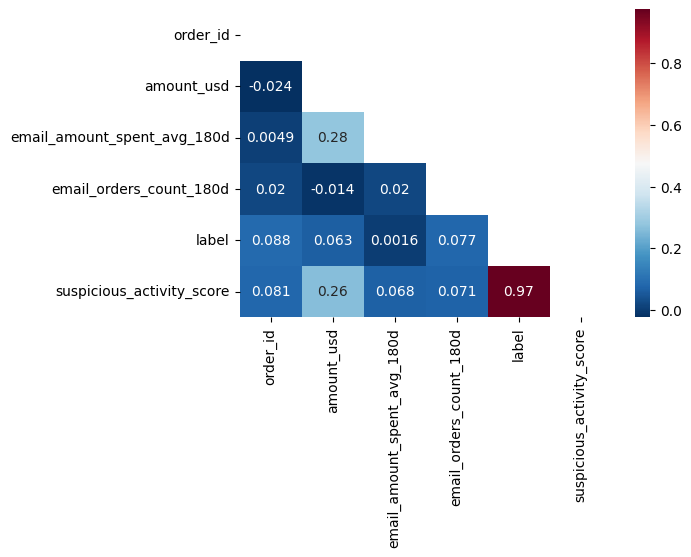

In [175]:
# Adding this after getting ROCAUC of 1.0
cor_mat = data.corr(numeric_only=True)
lower_triangle_mask = np.triu(np.ones(cor_mat.shape)).astype(bool)
cor_mat_lower = cor_mat.mask(lower_triangle_mask)

plt.figure(figsize = (6,4)) 

sns.heatmap(cor_mat_lower, 
            annot=True, 
            cmap='RdBu_r');

In [21]:
#Explore the data to identify new columns that we may find relevant to the problem

# Assess mutual information - is payment method worth keeping or should we drop?

In [252]:
data_cleaner_check.billing_address_country_code.value_counts()

billing_address_country_code
GB    28940
RU    13752
US    12426
DE    10449
IT     9279
      ...  
VG        1
PY        1
LC        1
VC        1
BO        1
Name: count, Length: 166, dtype: int64

In [ ]:
import pandas as pd

TARGET_COMBINATIONS = {
    "Unknown__mastercard",
    "credit__visa",
    "credit__mastercard"
}

NORMALISED_TARGETS = {value.lower() for value in TARGET_COMBINATIONS}

def add_bin_brand_type_flag(dataframe: pd.DataFrame) -> pd.DataFrame:
    
    required_columns = {"bin_type", "bin_brand"}
    missing = required_columns - set(dataframe.columns)
    if missing:
        raise KeyError(f"Dataframe must include columns {required_columns}. Missing: {missing}")

    df = dataframe.copy()

    combined = (
        df["bin_type"].fillna("Unknown").astype(str).str.strip()
        + "__"
        + df["bin_brand"].fillna("Unknown").astype(str).str.strip()
    )

    mask = combined.str.lower().isin(NORMALISED_TARGETS)
    df["bin_brand_type"] = mask.astype(int)
    return df

In [257]:
import pycountry_convert as pc
def country_to_continent(code):
    try:
        country_alpha2 = code.upper()
        continent_code = pc.country_alpha2_to_continent_code(country_alpha2)
        continent_name = pc.convert_continent_code_to_continent_name(continent_code)
        return continent_name
    except:
        return "Unknown"

def add_bin_brand_type_flag(df):

    valid_combos = {"unknown__mastercard", "credit__visa", "credit__mastercard"}

    df["bin_brand_type"] = (
        df["bin_type"].fillna("unknown").str.strip().str.lower() + "__" +
        df["bin_brand"].fillna("unknown").str.strip().str.lower()
    ).isin(valid_combos).astype(int)

    return df

In [282]:
#Create the new columns via custom transformer

class FeatureEngineering(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass
    
    def fit(self, X=None, y=None, **fit_params):
        return self
    
    def transform(self, X):
        _df = X.copy()

        #Create features derived from order_date (day of the week, period of the day, etc.)
        _df["order_year"] = _df["order_date"].dt.year
        _df["order_month"] = _df["order_date"].dt.month
        _df["order_day_of_month"] = _df["order_date"].dt.day
        _df["order_dayofweek"] = _df["order_date"].dt.dayofweek             # 0=Mon, 6=Sun
        _df["order_weekofyear"] = _df["order_date"].dt.isocalendar().week
        _df["order_hour"] = _df["order_date"].dt.hour
        _df["order_is_weekend"] = _df["order_dayofweek"].isin([5, 6]).astype(int)
        
        # part of day (binned by hour)
        # bin order hours (0–23) into time-of-day categories: dawn, morning, afternoon, evening
        _df["order_daypart"] = pd.cut(
            _df["order_hour"],
            [-1, 5, 11, 17, 23],
            labels=["dawn", "morning", "afternoon", "evening"] 
        )
        
        #Create features around card expiration date
        _df['card_expiry_is_missing'] = _df['card_expiration_date'].isna().astype(int)
        
        _df['card_days_to_expire'] = (_df["card_expiration_date"] - _df["order_date"]).dt.days.astype("float")
        _df["card_days_to_expire"] = _df["card_days_to_expire"].fillna(-1)
        
        _df["card_is_expired"]      = (_df["card_days_to_expire"] < 0).astype("Int64").fillna(0).astype(int)
        _df["months_until_expiry"] = ((_df.card_expiration_date.dt.year - _df.order_date.dt.year) * 12) + (_df.card_expiration_date.dt.month - _df.order_date.dt.month)


        #Shipment method type data treatment
        _df["ship_tokens"] = _df["shipping_method_type"].str.split(";")
        
        _df["ship_primary"] = _df["ship_tokens"].apply(lambda x: x[0] if isinstance(x, list) else "UNKNOWN")
        _df["ship_length"] = _df["ship_tokens"].apply(lambda x: len(x) if isinstance(x, list) else 0)
        _df["ship_num_E"] = _df["ship_tokens"].apply(lambda x: x.count("E") if isinstance(x, list) else 0)
        _df["ship_num_S"] = _df["ship_tokens"].apply(lambda x: x.count("S") if isinstance(x, list) else 0)
        _df["ship_ratio_E"] = (_df["ship_num_E"] / _df["ship_length"]).replace([np.inf, np.nan], 0)
        _df["ship_unique"] = _df["ship_tokens"].apply(lambda x: len(set(x)) if isinstance(x, list) else 0)
        # does the sequence contain both E and S?
        _df["ship_has_both"] = _df["ship_tokens"].apply(lambda x: int("E" in x and "S" in x) if isinstance(x, list) else 0)

        
        #Create features around country codes - billing address and shipping address
        _df["billing_continent"]  = _df["billing_address_country_code"].apply(country_to_continent)
        _df["shipping_continent"] = _df["shipping_address_country_code"].apply(country_to_continent)
        
        _df["same_country"]   = (_df["billing_address_country_code"] == _df["shipping_address_country_code"]).astype(int)
        _df["same_continent"] = (_df["billing_continent"] == _df["shipping_continent"]).astype(int)
    
        #Engineering bin type and brand
        #_df = add_bin_brand_type_flag(_df)   
        
        #Drop dates as we've done all our feature engineering using them already
        _df = _df.drop(columns=['order_date', 'card_expiration_date'])

        #Drop suspicious high correlation columns
        _df = _df.drop(columns = ['suspicious_activity_score'])
        
        #Remove columns that have no variance
        _df = _df.drop(columns = ['order_id'])
        
        
        
        #Remove non numerical columns with too many values so we go straight to one hot for all categoricals, study them better later
        _df = _df.drop(columns=['ship_tokens','shipping_method_type'])
        #_df = df.drop(columns=['billing_address_country_code', 'shipping_address_country_code'])
        
        return _df 

In [283]:
feature_eng = FeatureEngineering()
treated_data = feature_eng.fit_transform(data_cleaner_check)
treated_data.head()

,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,bin_brand,bin_type,...,ship_length,ship_num_E,ship_num_S,ship_ratio_E,ship_unique,ship_has_both,billing_continent,shipping_continent,same_country,same_continent
0,611.03,payment_method_2,SA,SA,avs_code_8,0.000000,0.0,returning,mastercard,credit,...,1,1,0,1.0,1,0,Asia,Asia,1,1
1,334.44,payment_method_1,FR,FR,avs_code_1,591.141667,6.0,returning,NaN,NaN,...,1,0,1,0.0,1,0,Europe,Europe,1,1
2,611.85,payment_method_1,HK,HK,avs_code_1,0.000000,0.0,returning,NaN,NaN,...,2,2,0,1.0,1,0,Asia,Asia,1,1
3,198.18,payment_method_2,RU,RU,avs_code_5,473.027368,38.0,returning,visa,debit,...,1,1,0,1.0,1,0,Europe,Europe,1,1
4,434.71,payment_method_3,HK,HK,avs_code_5,0.000000,0.0,returning,NaN,NaN,...,1,1,0,1.0,1,0,Asia,Asia,1,1


In [284]:
#date_related_columns = ['order_date', 'card_expiration_date','card_expiry_is_missing','card_days_to_expire','card_is_expired','card_exp_within_30d', 'card_exp_within_90d']
#treated_data[date_related_columns].tail()

In [285]:
#treated_data[date_related_columns].card_expiry_is_missing.value_counts()
data.select_dtypes(include=["object", "category"]).nunique()

order_date                       174799
payment_method                        8
billing_address_country_code        166
shipping_address_country_code       166
avs_code                             24
session_visitor_type                  2
shipping_method_type                156
card_expiration_date                187
bin_brand                            10
bin_type                              3
dtype: int64

### Feature Selection

##### Apply Mutual Info to assess if the data we are engineering is relevant

In [286]:
#Fill in missings in categorical with unknown so we can compute the mutual info 
cat_cols = treated_data.select_dtypes(include=["object", "category"]).columns
for col in cat_cols:
    treated_data[col] = treated_data[col].fillna(treated_data[col].mode()[0])


treated_data.isnull().sum()


amount_usd                           0
payment_method                       0
billing_address_country_code         0
shipping_address_country_code        0
avs_code                             0
email_amount_spent_avg_180d          0
email_orders_count_180d              0
session_visitor_type                 0
bin_brand                            0
bin_type                             0
label                                0
order_year                           0
order_month                          0
order_day_of_month                   0
order_dayofweek                      0
order_weekofyear                     0
order_hour                           0
order_is_weekend                     0
order_daypart                        0
card_expiry_is_missing               0
card_days_to_expire                  0
card_is_expired                      0
months_until_expiry              58945
ship_primary                         0
ship_length                          0
ship_num_E               

In [287]:
#Convert categoricals to dummies

treated_data_encoded = pd.get_dummies(
    treated_data,
    columns=cat_cols,
    prefix=cat_cols,         # use the column name as prefix
    prefix_sep='__',         # double underscore is clean and readable
    drop_first=False,
    dummy_na=False
)
treated_data_encoded.shape

(190343, 428)

In [288]:
#mi = mutual_info_classif(treated_data_encoded.drop(columns=['label']), treated_data_encoded['label'], discrete_features='auto', random_state=42)

#mi_df = pd.DataFrame({
#    'feature': treated_data_encoded.drop(columns=['label']).columns,
#    'mutual_info': mi
#}).sort_values('mutual_info', ascending=False)

#print(mi_df.head(20))

### Baseline - Model Training and Evaluation

#### Data Pipeline Prep

In [289]:
treated_data.select_dtypes(include=["object", "category"]).nunique()

payment_method                     8
billing_address_country_code     166
shipping_address_country_code    166
avs_code                          24
session_visitor_type               2
bin_brand                         10
bin_type                           3
order_daypart                      4
ship_primary                       8
billing_continent                  7
shipping_continent                 7
dtype: int64

In [290]:
#Split the data - careful for imbalances, stratify needed, over/under sampling needed?
#Create data pipeline this and that for numerical, this and that for categorical, this and that..
numerical_pipeline = Pipeline(steps=[
    ("num_imputer", SimpleImputer(strategy='median')),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("cat_imputer", SimpleImputer(strategy="constant", fill_value = "Unknown")),
    ("onehot", OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocess = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, selector(dtype_include=np.number)),
        ("categorical", categorical_pipeline, selector(dtype_exclude=np.number)),
    ]
)

In [291]:
#Split data with stratify
X = data.drop(columns=[target_column])
y = data[target_column]

    
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size = 0.3, stratify = y, random_state = 42)

In [292]:
#Fit the model
pipeline = Pipeline(steps=[
    ('data_clean', DataCleaner()),
    ('feature_engineering',FeatureEngineering()),
    ('data_type_prep', preprocess),
    ('baseline_model', RandomForestClassifier(n_estimators=50,max_depth=None,min_samples_leaf=2,max_features="sqrt",class_weight="balanced_subsample", n_jobs = -1, random_state=42)),
])

pipeline.fit(X_train, y_train)

,steps,"[('data_clean', ...), ('feature_engineering', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [293]:
#Calculate metrics of interest

probas_train = pipeline.predict_proba(X_train)[:, 1]
probas_valid = pipeline.predict_proba(X_valid)[:, 1]

roc_auc_train = roc_auc_score(y_train, probas_train)
roc_auc_valid = roc_auc_score(y_valid, probas_valid)

print(f"ROC AUC  Train: {roc_auc_train}")
print(f"ROC AUC  Valid: {roc_auc_valid}")


ROC AUC  Train: 0.9976372685831393
ROC AUC  Valid: 0.9689173810711494


In [133]:
#Our feature engineering iterated baseline score is:
#ROC AUC  Train: 0.9972398829368564
#ROC AUC  Valid: 0.9688474401425855

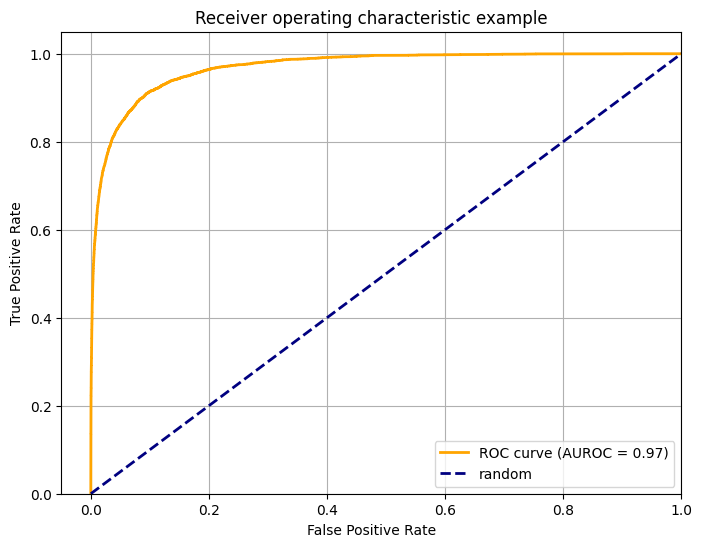

In [294]:
#Plot ROCAUC Curve
roc_auc = roc_auc_score(y_valid, probas_valid)
fpr, tpr, thresholds = roc_curve(y_score=pipeline.predict_proba(X_valid)[:,1], y_true=y_valid)
def plot_roc_curve(roc_auc, fpr, tpr):
    
    plt.figure(figsize=(8,6))
    lw = 2
    plt.plot(fpr, tpr, color='orange', lw=lw, label='ROC curve (AUROC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--', label='random')
    plt.xlim([-0.05, 1.0])
    plt.ylim([0.0, 1.05])
    plt.grid()
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic example')
    plt.legend(loc="lower right")
    plt.show()
plot_roc_curve(roc_auc, fpr, tpr)

In [195]:
#Optional - do we need to check for ROC AUC across different segments of our data to guarantee fairness?

##### Understand Feature Importances

In [295]:
rf = pipeline.named_steps["baseline_model"]

feature_names = pipeline.named_steps["data_type_prep"].get_feature_names_out()

feat_imp = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": rf.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print(feat_imp[feat_imp['importance']<=0.005])

                                          feature  importance
40   categorical__billing_continent_South America    0.004668
41          categorical__billing_continent_Europe    0.004607
42            categorical__billing_continent_Asia    0.004552
43           categorical__shipping_continent_Asia    0.004234
44   categorical__billing_address_country_code_KR    0.004090
..                                            ...         ...
419                   categorical__ship_primary_C    0.000000
420  categorical__billing_address_country_code_GU    0.000000
421  categorical__billing_address_country_code_HT    0.000000
422  categorical__billing_address_country_code_HN    0.000000
423  categorical__billing_address_country_code_GY    0.000000

[384 rows x 2 columns]


In [ ]:
# Possible iteration: Define function to drop columns that are not relevant

### Iteration/Evolution - Model Training and Evaluation

In [166]:
def make_pipeline_with(estimator):
    return Pipeline(steps=[
        ("data_clean", DataCleaner()),
        ("feature_engineering", FeatureEngineering()),  # remove if not using
        ("data_type_prep", preprocess),
        ("model", estimator),
    ])

neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()


model_definition_grid = {
    "logistic": {
        "model": LogisticRegression(
            solver="saga",
            class_weight="balanced",
            max_iter=5000,
            n_jobs=-1,
            random_state=42
        ),
        "params": {
            "C": [0.1, 1.0, 3.0],            
            "penalty": ["l1", "l2"],        
            "tol": [1e-3]
        }
    },
    "random_forest_baseline": {
        "model": RandomForestClassifier(
            n_estimators=50,
            max_depth=None,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ),
        "params": {}  
    },
    
    "random_forest": {
        "model": RandomForestClassifier(
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ),
        "params": {
            "n_estimators": [300, 600],
            "max_depth": [None, 12, 24],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", "log2"]
        }
    },
    
    "xgb": {
        "model": XGBClassifier(
            tree_method="hist",
            objective="binary:logistic",
            eval_metric="aucpr",
            scale_pos_weight=neg_pos_ratio,
            n_estimators=400,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            max_depth=6,
            reg_lambda=1.0,
            n_jobs=-1,
            random_state=42,
            use_label_encoder=False
        ),
        "params": {
            "n_estimators": [300, 600],
            "learning_rate": [0.03, 0.05, 0.1],
            "max_depth": [4, 6, 8],
            "min_child_weight": [1, 3, 6],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0],
            "reg_lambda": [0.5, 1.0, 2.0],
            "gamma": [0, 1],
            "scale_pos_weight": [neg_pos_ratio * s for s in (0.7, 1.0, 1.3)]
        }
    }
}

In [167]:
scores = []
for model_name, model_parameters in model_definition_grid.items():
    model_grid = GridSearchCV(make_pipeline_with(model_parameters['model']), model_parameters['params'], cv = 3)
    model_grid.fit(X_train, y_train)
    
    predictions = model_grid.best_estimator_.predict(X_valid)

    print(model_name, " Best MAE: ", mae)

    scores.append({
        'model': model_name,
        'best_params': model_grid.best_params_,
        'best_score': model_grid.best_score_,
        'best_valid_mae': mae
    })
    
    results_df = pd.DataFrame(scores).sort_values("Validation MAE", ascending=True).reset_index(drop=True)
    print(results_df.to_markdown(index=False))

ValueError: Invalid parameter 'C' for estimator Pipeline(steps=[('data_clean', <__main__.DataCleaner object at 0x7d3ffad1ff80>),
                ('feature_engineering', FeatureEngineering()),
                ('data_type_prep',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('num_imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7d3f...
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                

In [144]:
print(scores)

NameError: name 'scores' is not defined

### Submission

In [297]:
#Load Test Data and do basic check
X_test = pd.read_csv("data/test.csv")
X_test['id']=X_test['order_id']
X_test = X_test.set_index('id')
X_test.head()

,order_id,order_date,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,shipping_method_type,card_expiration_date,bin_brand,bin_type,suspicious_activity_score
id,,,,,,,,,,,,,,,
191025041,191025041,2022-08-02 18:32:51,121.90,payment_method_1,GB,GB,avs_code_1,NaN,NaN,returning,S,NaN,NaN,NaN,0
191796174,191796174,2022-08-16 14:00:44,98.74,payment_method_1,GB,GB,avs_code_1,NaN,NaN,new,S,NaN,NaN,NaN,0
202905772,202905772,2022-11-22 02:49:31,117.03,payment_method_2,MX,MX,avs_code_3,NaN,NaN,returning,E,09/2026,mastercard,credit,0
204355210,204355210,2022-11-25 09:49:33,629.51,payment_method_1,GB,GB,avs_code_1,NaN,NaN,returning,S,NaN,NaN,NaN,0
190036435,190036435,2022-08-01 14:21:45,427.32,payment_method_2,BE,BE,avs_code_3,NaN,NaN,returning,S,05/2027,visa,debit,0


In [298]:
#Use pipeline to predict probas
y_scores_final = pipeline.predict_proba(X_test)[:, 1]

In [299]:
#Prepare submission file - IMPORTANT: submission id name needs to be renamed
submission = pd.Series(y_scores_final,index=X_test.index, name='result')
submission.to_csv("data/submission_1.csv")